# 04 · Hand-pick sample frames

For the next experiments we want a few **hand-chosen frames**: a bouquet
close-up, a wide shot, hands in the way, a street scene with no flowers at
all... The tool below lets you scrub through the video and pick the ones you
want.

**How to use it**

* The row of buttons jumps **-1000 / -100 / -10 / -1 / +1 / +10 / +100 /
  +1000 frames** (at 30 fps that is 33 s, 3.3 s, 0.33 s and one frame). Big
  jumps to find the section, small ones to fine-tune.
* **Pick this frame** adds the current frame to your list (press it again to
  unpick). The list on the bottom left shows your picks; select one and use
  **Show selected** or **Remove selected**.
* **Save picks** writes them to `data/raw/picks/<video>_frames.json`
  (git-ignored), so later notebooks can load exactly the same frames.
* You can also type a frame number or a time in seconds and press **Go**.

The widget is interactive: **run the notebook live** (VS Code or Jupyter). A
saved copy of the notebook only shows the first frame.

Contents: 1 Load the video · 2 The picker · 3 Your picks · 4 Using the picks
elsewhere · 5 Without buttons

## 1 · Load the video

Same video as the earlier notebooks (downloaded once and reused).

In [1]:
from IPython.display import display

from bouquet_checker import video
from bouquet_checker.framepicker import FramePicker

VIDEO_URL = "https://www.youtube.com/watch?v=QSVyyrKea14"

path = video.download_video(VIDEO_URL, max_height=720)
info = video.video_info(path)
print(f"{path.name}: {info.width}x{info.height} @ {info.fps:.0f} fps, "
      f"{info.frame_count:,} frames ({info.duration_s:.0f} s)")

QSVyyrKea14.mp4: 1280x720 @ 30 fps, 11,968 frames (399 s)


## 2 · The picker

Run this cell and use the buttons. `start` is the frame it opens on (3000 is
100 s in, where the bouquets begin); change it or type another frame in the
box.

**Tip:** pick *different* situations, not ten near-identical frames: a close
bouquet, a wide shot of the shop, a hand holding flowers, a shelf, a street
scene with no flowers (a good false-alarm test).

In [3]:
picker = FramePicker(path, start=3000)
picker.ui(width=760)

## 3 · Your picks

Run this cell any time to see what you have picked so far as a contact sheet.

18 frame(s) picked: [1620, 3040, 3057, 3073, 3273, 3300, 3510, 3529, 3560, 3582, 3615, 3945, 4027, 4283, 4288, 4873, 5048, 5445]


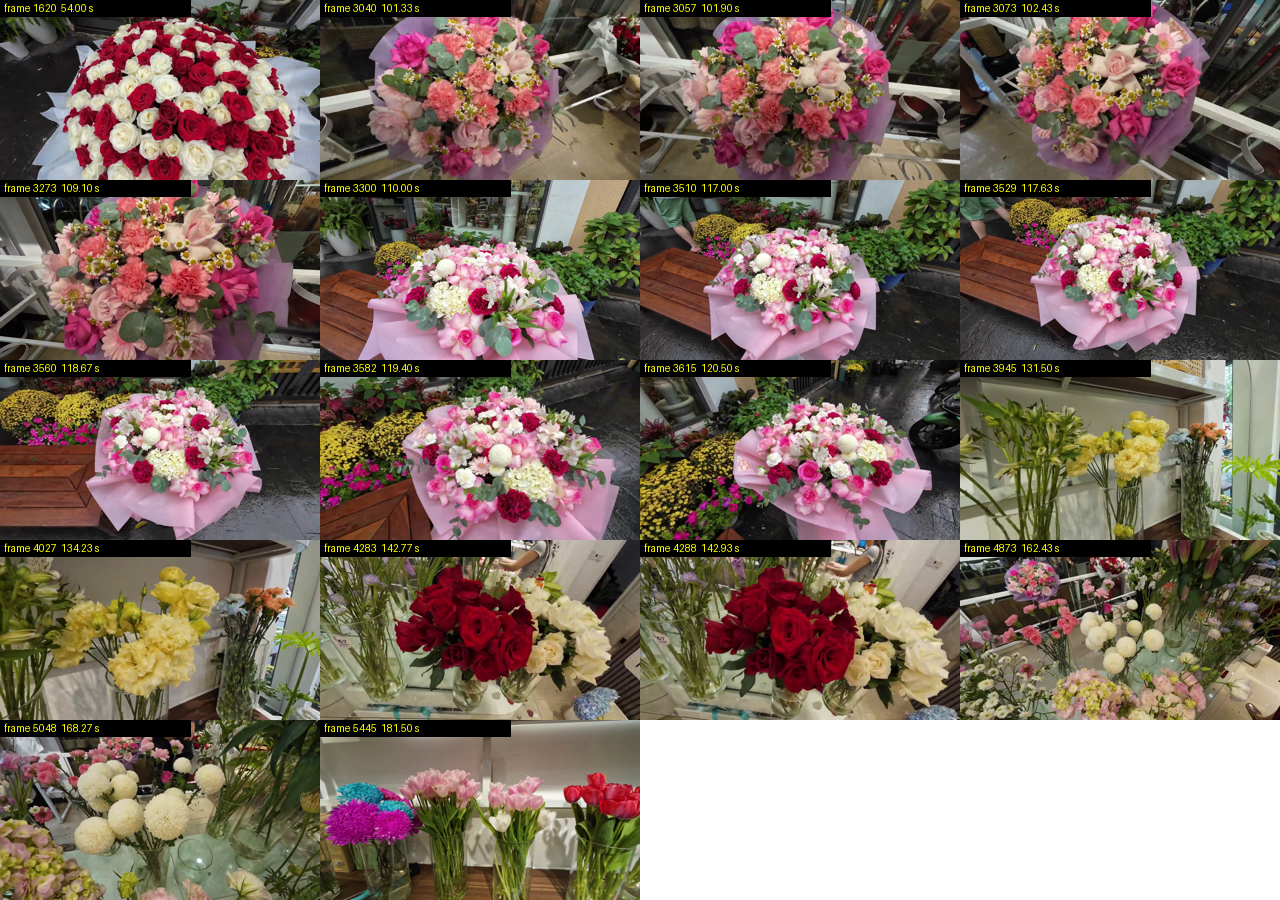

In [4]:
print(f"{len(picker.picks)} frame(s) picked: {picker.picks}")
sheet = picker.contact_sheet(cols=4)
if sheet is None:
    print("nothing picked yet: use the buttons above, then run this cell again")
else:
    display(sheet)

Save and restore (the **Save picks** button does the same as `save()`):

In [5]:
# picker.save()        # write the picks to the JSON file
# picker.load()        # restore them (add merge=True to keep the current ones)
print("picks file:", picker.picks_path)
print("exists:", picker.picks_path.exists())

picks file: C:\Users\carl0\vsc\cat-project\data\raw\picks\QSVyyrKea14_frames.json
exists: False


## 4 · Using the picks in another notebook

Load the saved picks and get the frames as ordinary PIL images:

In [5]:
# with FramePicker(path) as p:
#     p.load()
#     frames = p.frames()                      # list of Frame(index, time_s, image)
#     images = [f.image for f in frames]

## 5 · Without buttons

Everything the buttons do is a plain method, so you can script it (handy if
widgets do not render in your editor):

In [6]:
# picker.goto(3210)          # jump to an exact frame
# picker.jump(+10)           # ... or by a number of frames (negative = back)
# picker.goto_time(107.0)    # ... or to a time in seconds
# picker.pick()              # pick the current frame
# picker.frame().image       # look at it
# picker.close()             # release the video file when you are done